# General

In [1]:
import os
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
for gpu in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(gpu, True)

# Data

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = keras.datasets.mnist.load_data()

In [3]:
x_train = x_train_raw.astype('float32') / 255.0
x_test = x_test_raw.astype('float32') / 255.0
print('Training:', x_train.shape, 'Test:', x_test.shape)

Training: (60000, 28, 28) Test: (10000, 28, 28)


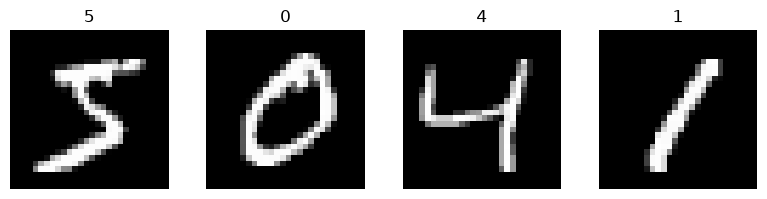

In [4]:
fig, axs = plt.subplots(1, 4, figsize=(8, 2))
for i, ax in enumerate(axs):
    ax.imshow(x_train[i].reshape(28, 28), cmap='gray')
    ax.set_title(str(y_train[i]))
    ax.axis('off')
plt.tight_layout()
plt.show()

# Training

Stop at 99% training accuracy, before epoch 9. The maximum is 10 epochs.

In [5]:
class myCallback(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        accuracy = (logs or {}).get('accuracy')
        if accuracy is not None and accuracy >= 0.99:
            print('Reached 99% accuracy so cancelling training!')
            self.model.stop_training = True

In [6]:
callbacks = myCallback()
model = keras.Sequential([
    layers.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dense(10, activation='softmax')
])
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist = model.fit(x_train, y_train, epochs=10, batch_size=128, callbacks=[callbacks], verbose=2)

Epoch 1/10
469/469 - 3s - 6ms/step - accuracy: 0.9159 - loss: 0.3024
Epoch 2/10
469/469 - 1s - 1ms/step - accuracy: 0.9628 - loss: 0.1311
Epoch 3/10
469/469 - 1s - 1ms/step - accuracy: 0.9746 - loss: 0.0893
Epoch 4/10
469/469 - 1s - 1ms/step - accuracy: 0.9812 - loss: 0.0658
Epoch 5/10
469/469 - 1s - 1ms/step - accuracy: 0.9863 - loss: 0.0503
Epoch 6/10
469/469 - 1s - 1ms/step - accuracy: 0.9899 - loss: 0.0388
Epoch 7/10
Reached 99% accuracy so cancelling training!
469/469 - 1s - 2ms/step - accuracy: 0.9926 - loss: 0.0299


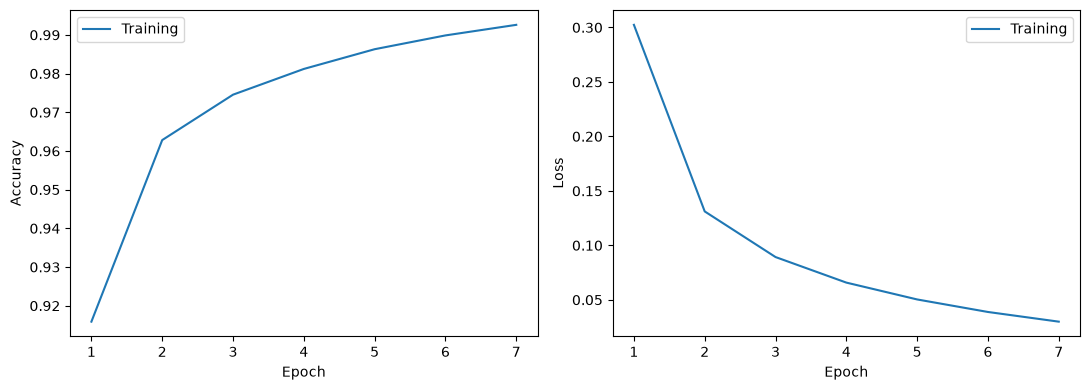

In [7]:
history = pd.DataFrame(hist.history)
epochs = np.arange(1, len(history) + 1)

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric in zip(axs, ['accuracy', 'loss']):
    ax.plot(epochs, history[metric], label='Training')
    if f'val_{metric}' in history:
        ax.plot(epochs, history[f'val_{metric}'], label='Validation')
    ax.set_xlabel('Epoch')
    ax.set_ylabel(metric.capitalize())
    ax.legend()
plt.tight_layout()
plt.show()

# Results

In [8]:
loss, accuracy = hist.model.evaluate(x_test, y_test, verbose=0)
result = {
    'part': 'part1',
    'epochs': len(hist.epoch),
    'train_accuracy': hist.history['accuracy'][-1],
    'test_loss': loss,
    'test_accuracy': accuracy
}
display(pd.DataFrame([result]))

,part,epochs,train_accuracy,test_loss,test_accuracy
0,part1,7,0.9926,0.071965,0.9778


# Saving

In [9]:
hist.model.save('models/part1.keras')

# Summary

Перцептрон досяг **99.26%** навчальної точності за **7 епох**. Callback зупинив навчання при першому досягненні 99%, раніше дев'ятої епохи.

На 10 000 тестових зображеннях точність становила **97.78%**, втрати - 0.0720. Умова зупинки стосується навчальних даних, тому не означає такої самої точності на тестових.